# 3. Resistance burden and encrypted-AMP opportunity

Question: do ATB genomes with more annotated AMR determinants have greater AMP
richness, stronger predicted activity among qualifying candidates, or greater
candidate-cluster diversity at equal sampling effort?

**Saved regression outputs use simulated data.** This notebook tests a framework,
not an observed AMR–AMP or co-evolution relationship. Genome AMR burden refers to
the source organism, whereas an AMP's target panel refers to organisms against
which the predictor estimates activity. These are different biological roles.

In [1]:
from pathlib import Path
import os, sys, json, platform, subprocess
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/genomespot_lens/amp_study.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from genomespot_lens.amp_study import (
    TRAITS, load_bundle, prepare_cohort, analysis_subset, standardized,
    fit_nb, effect_table, grouped_ecology_cv, tree_covariance,
    build_phylogenetic_nb,
)

# Explicit demonstration mode. Change to "real" only after preparing the contract.
# No automatic fallback to simulated data is permitted.
MODE = os.environ.get("AMP_STUDY_MODE", "demo")
assert MODE in {"demo", "real"}
COHORT = os.environ.get("AMP_STUDY_COHORT", "atb")
DATA_DIR = (ROOT / "examples/amp-study/demo") if MODE == "demo" else Path(
    os.environ.get("AMP_STUDY_DATA", str(ROOT / "data/amp-study")))
RUN_PHYLO_MCMC = os.environ.get("AMP_STUDY_PHYLO_MCMC", "0") == "1"
SEED = 23
LABEL = "SIMULATED DATA — software demonstration" if MODE == "demo" else "REAL COHORT — observational associations"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(Markdown(f"**{LABEL}**"))
print("Python", platform.python_version(), "| cohort:", COHORT, "| bundle:", "examples/amp-study/demo" if MODE == "demo" else DATA_DIR.name)
FIG_DIR = ROOT / "runs/amp-study/figures" / MODE
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    figure.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

**SIMULATED DATA — software demonstration**

Python 3.11.16 | cohort: atb | bundle: examples/amp-study/demo


In [2]:
# Actual published-source audit, independent of the simulated analysis below.
source_audit = json.loads((ROOT / "examples/amp-study/source-audit.json").read_text())
display(pd.DataFrame([
    {"source": "Archaeome complete positive-score catalog", "records": source_audit["archaeome"]["score_rows"], "genome richness ready": False},
    {"source": "Archaeome selected source mappings", "records": source_audit["archaeome"]["selected_mapping_rows"], "genome richness ready": False},
]))
source_dir = ROOT / "examples/amp-study/source-genomes"
if source_dir.exists():
    # Genuine GenomeSPOT outputs. They are not joined to invented AMP counts.
    real_predictions = pd.read_csv(source_dir / "genomespot.csv")
    display(real_predictions[real_predictions.target.isin(TRAITS.values())])
reconstruction_dir = ROOT / "examples/amp-study/archaeome-reconstruction"
reconstruction = json.loads((reconstruction_dir / "audit.json").read_text())
display(pd.DataFrame({"reported": reconstruction["expected_counts"],
                      "reconstructed": reconstruction["observed_counts"]}))
source_taxa = pd.read_csv(reconstruction_dir / "source_taxa.csv")
display(source_taxa[["reviewed_protein_records", "distinct_screened_fragments",
                     "distinct_high_scoring_peptides"]].describe())
print("Actual reconstructed taxa:", len(source_taxa), "| zero catalog hits:",
      reconstruction["taxa_with_zero_catalog_hits"], "| all published positives map:",
      reconstruction["all_positive_peptides_mapped"])
print("These are source-taxon reviewed-protein screens; use verified assembly joins for genome models.")
batch_dir = ROOT / "examples/amp-study/reconstructed-genomes"
if (batch_dir / "prediction_audit.json").exists():
    batch = json.loads((batch_dir / "prediction_audit.json").read_text())
    display(pd.Series(batch["counts"], name="ACTUAL current-reference batch checks"))
    print("Actual GenomeSPOT prediction rows:", batch["prediction_rows"])
    print(batch["candidate_caveat"])
print("ATB Results and Methods disagree on the MIC selection rule; resolve before a real ATB run.")
print("Source-screen linkage: see study/source-search.md and study/data-contract.md")

,source,records,genome richness ready
0,Archaeome complete positive-score catalog,12623,False
1,Archaeome selected source mappings,265,False


,genome_id,target,value,error,is_novel,warning,units
0,GCF_000091665.1,temperature_optimum,78.66277683556687,7.414129,False,NaN,C
3,GCF_000091665.1,ph_optimum,5.653625708702203,1.278201,False,NaN,pH
6,GCF_000091665.1,salinity_optimum,1.3394815190900058,1.877941,True,NaN,% w/v NaCl
9,GCF_000091665.1,oxygen,not tolerant,0.999991,True,NaN,probability
10,GCF_000011105.1,temperature_optimum,91.07637426802242,5.791886,False,NaN,C
13,GCF_000011105.1,ph_optimum,6.599838846769681,0.960230,False,NaN,pH
16,GCF_000011105.1,salinity_optimum,0.3534652516594101,1.873083,False,NaN,% w/v NaCl
19,GCF_000011105.1,oxygen,not tolerant,0.997884,False,NaN,probability
20,GCF_000008665.1,temperature_optimum,83.06935213778993,6.773858,False,NaN,C
23,GCF_000008665.1,ph_optimum,6.49814827121021,1.009838,False,NaN,pH


,reported,reconstructed
protein_records,19710,19710
distinct_proteins,18677,18677
source_taxa,233,233
distinct_screened_fragments,193331608,193331608
positive_catalog_rows,12623,12623


,reviewed_protein_records,distinct_screened_fragments,distinct_high_scoring_peptides
count,233.000000,2.330000e+02,233.000000
mean,84.592275,9.493362e+05,60.309013
std,182.176665,2.007127e+06,171.256962
min,1.000000,1.500000e+01,0.000000
25%,1.000000,1.724300e+04,0.000000
50%,4.000000,5.637300e+04,0.000000
75%,118.000000,1.187098e+06,32.000000
max,1787.000000,1.948918e+07,1821.000000


Actual reconstructed taxa: 233 | zero catalog hits: 128 | all published positives map: True
These are source-taxon reviewed-protein screens; use verified assembly joins for genome models.


historical_sources_contained               52
historical_sources_exact_full_proteins     47
genome_qc_pass                            103
prediction_success                        138
all_four_primary_traits_unflagged          89
preliminary_historical_join_candidate      24
Name: ACTUAL current-reference batch checks, dtype: int64

Actual GenomeSPOT prediction rows: 1380
Preliminary join candidates still require documented taxonomy, independent habitat, a rooted archaeal tree, composition/coverage controls and a frozen analysis. Failed QC and flagged traits are retained, not set to zero.
ATB Results and Methods disagree on the MIC selection rule; resolve before a real ATB run.
Source-screen linkage: see study/source-search.md and study/data-contract.md


The biological unit is a genome. AMP richness counts **distinct peptide sequences
per genome**, after exact parent/source mapping and a complete scoring panel.
The exposure counts the corresponding distinct sequences screened under one
fixed protocol, model version and target panel. Missing or failed screens remain
missing. Repeated parent copies and multiple target scores do not multiply counts.

Use each dataset/cohort separately. ATB's Results report any-target <80 µM, while Methods say median-panel ≤80 µM;
that conflict needs resolution before a real ATB analysis. The demo illustrates
an any-target rule. The archaeome study uses a separate mean-panel ≤100 µM rule. Preserve the
original rule in `bundle.json`; harmonizing thresholds also requires harmonized
screening and source coverage. Predicted MIC and measured MIC are distinct fields.

In [3]:
tables, spec, provenance, tree_path = load_bundle(DATA_DIR, COHORT, expected_kind=MODE)
cohort, candidate_table, hit_audit = prepare_cohort(tables, spec)
display(pd.Series(hit_audit, name="hit-table audit"))
display(pd.DataFrame({
    "genomes": [len(cohort)],
    "completed_screens": [int(cohort.screen_eligible.sum())],
    "quality_pass": [int(cohort.genome_qc_pass.sum())],
    "all_four_traits_unflagged": [int(cohort.all_traits_unflagged.sum())],
    "amr_successful": [int(cohort.amr_status.eq("PASS").sum())],
}))
assert not cohort.loc[~cohort.screen_eligible, "amp_count"].notna().any()
assert not cohort.loc[~cohort.amr_status.eq("PASS"), "amr_gene_count"].notna().any()

input_rows                            8776
nonexact_rows_excluded                   0
incomplete_panel_peptides_excluded       0
distinct_genome_peptide_hits          4388
Name: hit-table audit, dtype: int64

,genomes,completed_screens,quality_pass,all_four_traits_unflagged,amr_successful
0,384,376,373,374,375


## Build resistance burden without false zeros

Use AMRFinderPlus element type `AMR` only; exclude stress/virulence annotations.
Count distinct gene symbols as the primary burden and distinct reported drug
classes as a sensitivity measure. Retain locus IDs to identify duplicate calls.
A successful AMR run without hits contributes zero. Failed, not-run and absent
status entries contribute missing values. Do not interpret these genetic calls
as measured susceptibility, acquired resistance only, or interchangeable effects
of every determinant. An acquired-only analysis needs an independently curated
intrinsic/acquired classification and a fixed database release.

In [4]:
if COHORT != "atb":
    raise ValueError("This AMR analysis requires an ATB cohort with matched AMRFinderPlus results")
data, excluded = analysis_subset(cohort, require_traits=True, require_amr=True)
columns = [f"trait_{t}" for t in TRAITS] + ["gc_fraction", "log_proteome_aa", "amr_gene_count", "amr_class_count"]
data, scales = standardized(data, columns)
display(data[["genome_id", "species", "amr_gene_count", "amr_class_count", "amp_count", "n_screened"]].head())
display(cohort.amr_status.value_counts(dropna=False))

,genome_id,species,amr_gene_count,amr_class_count,amp_count,n_screened
0,SIM_0001,SIM_Species_0_0,7.0,4.0,11.0,31155
1,SIM_0002,SIM_Species_0_0,1.0,1.0,22.0,64908
2,SIM_0003,SIM_Species_0_0,5.0,4.0,29.0,134970
3,SIM_0004,SIM_Species_0_0,7.0,4.0,9.0,37633
4,SIM_0005,SIM_Species_0_0,5.0,4.0,26.0,137128


amr_status
PASS    375
FAIL      9
Name: count, dtype: int64

## Richness across and within species

Model counts with the screening offset, proteome size, GC, ecology and habitat.
The across-cohort model includes family effects. The within-species model uses
species fixed effects and requires actual AMR variation within at least ten
species. This helps distinguish a lineage's baseline biology from isolate-level
co-occurrence. It still cannot establish co-evolution or causality.

In [5]:
covariates = "z_log_proteome_aa + z_gc_fraction + z_trait_temperature + z_trait_ph + z_trait_salinity + z_trait_oxygen + C(habitat)"
across_formula = "amp_count ~ z_amr_gene_count + " + covariates + " + C(family)"
across_fit = fit_nb(data, across_formula)
across_effect = effect_table(across_fit, ["z_amr_gene_count"])
across_effect["comparison"] = "across cohort; family adjusted"
variable_species = data.groupby("species").amr_gene_count.nunique()
variable_species = variable_species[variable_species >= 2].index
within = data[data.species.isin(variable_species)].copy()
assert within.species.nunique() >= 10, "Too few species with within-species AMR variation"
within_formula = "amp_count ~ z_amr_gene_count + " + covariates + " + C(species)"
within_fit = fit_nb(within, within_formula)
within_effect = effect_table(within_fit, ["z_amr_gene_count"])
within_effect["comparison"] = "within species"
richness_effects = pd.concat([across_effect, within_effect], ignore_index=True)
display(richness_effects)
# Alternative burden definition is a prespecified sensitivity, not a second claim.
class_fit = fit_nb(data, across_formula.replace("z_amr_gene_count", "z_amr_class_count"))
display(effect_table(class_fit, ["z_amr_class_count"]))

,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh,comparison
0,z_amr_gene_count,0.312510,1.366852,1.268761,1.472526,1.951521e-16,1.951521e-16,across cohort; family adjusted
1,z_amr_gene_count,0.202689,1.224692,1.127957,1.329723,1.378399e-06,1.378399e-06,within species


,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh
0,z_amr_class_count,0.264608,1.302921,1.194246,1.421485,2.604351e-09,2.604351e-09


## Conditional potency and equal-effort diversity

Use each genome's median log10 predicted MIC among qualifying unique candidates,
requiring at least five candidates. Lower values imply stronger **predicted**
activity under the declared any-target or mean-panel rule. This is conditional
on passing the threshold; a hit-only catalog cannot estimate the potency of all
fragments. Include log(candidate count) to reduce count-dependent selection bias.
Never substitute a best-of-many MIC as the main potency endpoint.

For distinctness, use cohort-wide, independently generated peptide-cluster IDs
and analytical rarefaction to ten candidate sequences per genome. This controls
sampling count, but it does not prove novel sequence mechanisms. Missing clusters
leave diversity unavailable. Experimental MICs need a separate analysis preserving
target identities, assay conditions and left/right censoring; this code does not
replace censored values with an arbitrary numeric MIC.

In [6]:
import statsmodels.formula.api as smf
potency = data[data.n_potency_candidates.ge(5)].copy()
potency["log_amp_count"] = np.log(potency.amp_count)
potency = potency[potency.species.isin(variable_species)].copy()
assert len(potency) >= 100 and potency.species.nunique() >= 10
potency_formula = "median_predicted_log10_mic_um ~ z_amr_gene_count + log_amp_count + " + covariates + " + C(species)"
potency_fit = smf.ols(potency_formula, potency).fit(cov_type="cluster", cov_kwds={"groups": potency.species})
potency_effect = pd.DataFrame({"coefficient": [potency_fit.params["z_amr_gene_count"]], "ci_low": [potency_fit.conf_int().loc["z_amr_gene_count", 0]], "ci_high": [potency_fit.conf_int().loc["z_amr_gene_count", 1]], "p_value": [potency_fit.pvalues["z_amr_gene_count"]], "n_genomes": [len(potency)]})
display(potency_effect)
print("Multiplicative change in conditional predicted MIC per AMR SD:", 10 ** potency_effect.coefficient.iloc[0])
diversity = data.dropna(subset=["rarefied_cluster_richness_10"]).copy()
diversity["log_amp_count"] = np.log(diversity.amp_count)
diversity_model = None
if len(diversity) >= 100 and diversity.species.nunique() >= 10:
    diversity_formula = "rarefied_cluster_richness_10 ~ z_amr_gene_count + log_amp_count + " + covariates + " + C(family)"
    diversity_model = smf.ols(diversity_formula, diversity).fit(cov_type="cluster", cov_kwds={"groups": diversity.species})
    display(pd.DataFrame({"amr_coefficient": [diversity_model.params["z_amr_gene_count"]], "p_value": [diversity_model.pvalues["z_amr_gene_count"]], "n_genomes": [len(diversity)]}))
else:
    print("Cluster diversity: insufficient mapped clusters/qualifying genomes; result unavailable.")
# Three distinct endpoints form a testing family; report joint FDR adjustment.
from statsmodels.stats.multitest import multipletests
endpoint_p = {"within_species_richness": within_fit.pvalues["z_amr_gene_count"], "conditional_potency": potency_fit.pvalues["z_amr_gene_count"], "rarefied_diversity": diversity_model.pvalues["z_amr_gene_count"] if diversity_model is not None else np.nan}
endpoint_tests = pd.DataFrame({"endpoint": list(endpoint_p), "p_value": list(endpoint_p.values())})
endpoint_tests["q_value_bh"] = multipletests(endpoint_tests.p_value.fillna(1), method="fdr_bh")[1]
endpoint_tests.loc[endpoint_tests.p_value.isna(), "q_value_bh"] = np.nan
display(endpoint_tests)

,coefficient,ci_low,ci_high,p_value,n_genomes
0,-0.047139,-0.061534,-0.032743,1.381896e-10,228


Multiplicative change in conditional predicted MIC per AMR SD: 0.8971423660854042


,amr_coefficient,p_value,n_genomes
0,0.031425,0.50863,143


,endpoint,p_value,q_value_bh
0,within_species_richness,1.378399e-06,2.067598e-06
1,conditional_potency,1.381896e-10,4.145688e-10
2,rarefied_diversity,5.086299e-01,5.086299e-01


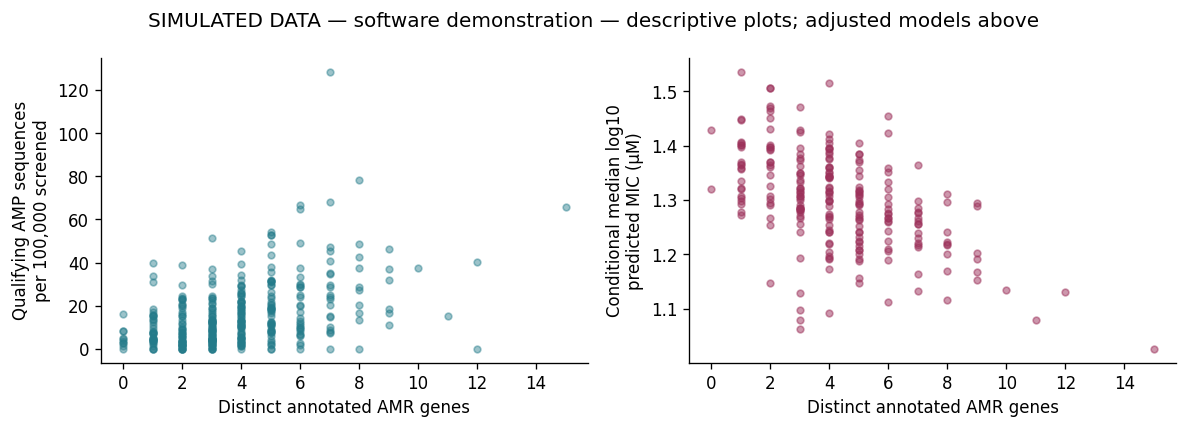

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(data.amr_gene_count, 100000 * data.amp_count / data.n_screened, alpha=.45, s=16, color="#247b8a")
axes[0].set(xlabel="Distinct annotated AMR genes", ylabel="Qualifying AMP sequences\nper 100,000 screened")
axes[1].scatter(potency.amr_gene_count, potency.median_predicted_log10_mic_um, alpha=.5, s=16, color="#9c315a")
axes[1].set(xlabel="Distinct annotated AMR genes", ylabel="Conditional median log10\npredicted MIC (µM)")
fig.suptitle(LABEL + " — descriptive plots; adjusted models above")
fig.tight_layout(); save_figure(fig, "resistance_descriptive"); plt.show()

## Phylogenetic sensitivity of the richness association

Use the same rooted-tree NB2 model with AMR burden as a predictor. Report disagreement between across-species, within-species and phylogenetic results rather than choosing the largest effect.

In [8]:
import patsy
import pymc as pm
if not spec.get("tree_rooted"):
    raise ValueError("A documented rooted tree with branch lengths is required")
phylo_cov = tree_covariance(tree_path, data.genome_id.tolist())
X_phylo = patsy.dmatrix('1 + z_amr_gene_count + z_log_proteome_aa + z_gc_fraction + z_trait_temperature + z_trait_ph + z_trait_salinity + z_trait_oxygen + C(habitat)', data, return_type="dataframe", NA_action="raise")
phylo_model = build_phylogenetic_nb(data, X_phylo, phylo_cov)
print("Built phylogenetic negative-binomial model:", len(data), "genomes,", X_phylo.shape[1], "fixed effects")
# A prior-predictive check exercises the actual mixed-model likelihood.
with phylo_model:
    prior_check = pm.sample_prior_predictive(samples=20, random_seed=SEED, var_names=["amp_count"])
print("Prior predictive dimensions:", dict(prior_check.prior_predictive.sizes))
if RUN_PHYLO_MCMC:
    import arviz as az
    with phylo_model:
        phylo_fit = pm.sample(draws=1000, tune=1000, chains=4, cores=2,
                              target_accept=.95, random_seed=SEED,
                              idata_kwargs={"log_likelihood": True})
        posterior_check = pm.sample_posterior_predictive(phylo_fit, random_seed=SEED)
    diagnostics = az.summary(phylo_fit, var_names=["beta", "phylo_sd", "nb_shape"])
    display(diagnostics)
    print("Divergences:", int(phylo_fit.sample_stats.diverging.sum()))
    all_rhat = float(az.rhat(phylo_fit).to_array().max())
    min_bulk_ess = float(az.ess(phylo_fit, method="bulk").to_array().min())
    print("All-parameter maximum R-hat:", all_rhat, "| minimum bulk ESS:", min_bulk_ess)
    az.plot_ppc(posterior_check, num_pp_samples=50)
    plt.suptitle(LABEL + " — posterior predictive check")
    plt.show()
    assert all_rhat < 1.01, "Chains have not converged"
    assert min_bulk_ess >= 400, "Insufficient effective samples"
    assert int(phylo_fit.sample_stats.diverging.sum()) == 0, "Resolve divergences"
    draws = phylo_fit.posterior.beta.stack(sample=("chain", "draw"))
    posterior_effects = pd.DataFrame({
        "coefficient": X_phylo.columns,
        "rate_ratio_median": np.exp(draws.median("sample").values),
        "rate_ratio_q025": np.exp(draws.quantile(.025, dim="sample").values),
        "rate_ratio_q975": np.exp(draws.quantile(.975, dim="sample").values),
    })
    display(posterior_effects)
    (ROOT / "runs").mkdir(exist_ok=True)
    phylo_fit.to_netcdf(ROOT / "runs" / ("resistance_phylo_" + MODE + ".nc"))
    posterior_effects.to_csv(ROOT / "runs" / ("resistance_phylo_effects_" + MODE + ".csv"), index=False)
else:
    print("Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Built phylogenetic negative-binomial model: 349 genomes, 10 fixed effects


Sampling: [amp_count, beta, nb_shape, phylo_sd, phylo_z]


Prior predictive dimensions: {'chain': 1, 'draw': 20, 'genome': 349}
Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.


In [9]:
OUT = ROOT / "runs/amp-study/resistance" / MODE
OUT.mkdir(parents=True, exist_ok=True)
data.to_csv(OUT / "cohort.csv", index=False)
excluded.to_csv(OUT / "excluded.csv", index=False)
richness_effects.to_csv(OUT / "richness_effects.csv", index=False)
potency_effect.to_csv(OUT / "conditional_potency.csv", index=False)
endpoint_tests.to_csv(OUT / "endpoint_tests.csv", index=False)
provenance["analysis"] = "resistance"
provenance["seed"] = SEED
provenance["run_phylogenetic_mcmc"] = RUN_PHYLO_MCMC
provenance["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
provenance["git_dirty"] = bool(subprocess.check_output(["git", "-C", str(ROOT), "status", "--porcelain"], text=True).strip())
provenance["bundle_settings"] = spec
provenance["packages"] = {p: version(p) for p in ["numpy", "pandas", "statsmodels", "pymc", "arviz", "biopython", "nbformat", "nbclient"]}
from genomespot_lens.core import sha256
provenance["analysis_code_sha256"] = {str(p.relative_to(ROOT)): sha256(p) for p in [ROOT / "src/genomespot_lens/amp_study.py", ROOT / "scripts/build_study_notebooks.py"]}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved results:", OUT.relative_to(ROOT))
display(Markdown("**Demonstration complete; simulated coefficients are not biological findings.**"
                 if MODE == "demo" else "**Review diagnostics, exclusions and sensitivity analyses before interpreting associations.**"))

Saved results: runs/amp-study/resistance/demo


**Demonstration complete; simulated coefficients are not biological findings.**

## Interpretation and follow-up

Co-occurrence can arise from taxonomy, mobile elements, clinical sampling,
annotation coverage and common sequence composition. A co-evolution argument
needs additional evidence such as concordant gains/losses on a suitable tree,
gene-context or transfer analysis and independent validation. Do not infer
natural expression, peptide release, ecological antagonism or clinical utility
from these predicted scores. Repeat with curated acquired-only AMR calls,
alternative database releases and measured susceptibility where available.

Sources and methods:

- [GenomeSPOT paper](https://doi.org/10.1101/2024.03.22.586313)
- [AllTheBacteria paper](https://doi.org/10.1101/2024.03.08.584059)
- [Archaeome paper](https://doi.org/10.1038/s41564-025-02061-0) and
  [Mendeley data deposit](https://doi.org/10.17632/d8yzgtdrcp.3)
- [AMR annotation documentation](https://allthebacteria.org/docs/amr/)
- [ATB phylogeny documentation](https://allthebacteria.org/docs/phylogeny/)
- [Negative-binomial likelihood](https://www.pymc.io/projects/docs/en/v5.10.4/api/distributions/generated/pymc.NegativeBinomial.html)

See `study/data-contract.md`, `study/analysis-plan.md` and `study/source-search.md`
for input definitions, reproducibility, exclusions and remaining source gaps.